# 03 – Models and grid search (PoQeMoN QoE project)

**Goal:** compare models that predict MOS (1–5), tune them with grid search, and measure them honestly.

**Plan**
1. **Why not a single test split?** We show that the score of one 80/20 split depends a lot on which users are drawn.
2. Evaluation protocol: **nested cross-validation grouped by user** (5 outer folds × 5 inner folds).
3. Prepare the columns (scaling + one-hot encoding) inside a **pipeline**.
4. Train a **baseline** and 4 models, each tuned by **grid search** inside every outer fold.
5. Compare them with **RMSE, MAE, QWK, macro F1 and accuracy** (mean ± standard deviation over the 5 folds).
6. **Confusion matrix:** which scores does the best model get right or wrong?
7. Decision tree depth: underfitting vs overfitting.
8. Extra: what happens if we use the QoF columns (data leakage)?
9. Which features matter most?

Run `01_data_cleaning.ipynb` first: it creates `pokemon_clean.csv`. In Colab, the first cell asks you to upload that file.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import (mean_squared_error, mean_absolute_error, cohen_kappa_score,
                             f1_score, accuracy_score, confusion_matrix)
from sklearn.inspection import permutation_importance

RANDOM_SEED = 42
N_OUTER = 5      # outer folds: used to MEASURE the models
N_INNER = 5      # inner folds: used by the grid search to CHOOSE the settings
SCORES = [1, 2, 3, 4, 5]

## 1. Load the clean data and define the columns
The column groups are the same as in notebook 1.

In [2]:
DATA_FILE = "pokemon_clean.csv"
if not os.path.exists(DATA_FILE):
    try:
        from google.colab import files   # only exists in Google Colab
        files.upload()                   # choose pokemon_clean.csv (made by notebook 1)
    except ImportError:
        raise FileNotFoundError("Run 01_data_cleaning.ipynb first: it creates pokemon_clean.csv")

df = pd.read_csv(DATA_FILE)

TARGET = "MOS"
GROUP = "user_id"
NUMERIC_FEATURES = [
    "QoA_VLCresolution", "QoA_VLCbitrate", "QoA_VLCframerate", "QoA_VLCdropped",
    "QoA_VLCaudiorate", "QoA_VLCaudioloss", "QoA_BUFFERINGcount", "log_BUFFERINGtime",
    "QoD_api-level", "QoU_sex", "QoU_age", "QoU_Ustedy",
]
CATEGORICAL_FEATURES = ["QoS_type", "QoS_operator", "QoD_model"]
LEAKAGE_FEATURES = ["QoF_begin", "QoF_shift", "QoF_audio", "QoF_video"]
MAIN_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X, y, groups = df[MAIN_FEATURES], df[TARGET].to_numpy(), df[GROUP].to_numpy()
print("Sessions:", len(df), "| Users:", df[GROUP].nunique())

Sessions: 1541 | Users: 181


## 2. Prepare the columns inside a pipeline

- **Numeric columns → `StandardScaler`**: puts every column on the same scale (mean 0, std 1). Important for Ridge; it does not change tree models.
- **Category columns → `OneHotEncoder`**: one yes/no column per category (for example `is_EDGE`).

**Why inside a pipeline?** In cross-validation, the scaler must learn its mean and std from the training folds only, never from the fold used for checking. The pipeline does this automatically, so no information leaks from the checking data.

In [3]:
def make_preprocessor(numeric_cols, categorical_cols):
    return ColumnTransformer([
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ])

def make_pipeline(estimator, numeric_cols=NUMERIC_FEATURES, categorical_cols=CATEGORICAL_FEATURES):
    return Pipeline([("prep", make_preprocessor(numeric_cols, categorical_cols)),
                     ("model", estimator)])

## 3. Why not a single test split?

In a first version we used **one** split: 80% of users for training, 20% (37 users) for the test.
Here we repeat this split with **10 different random seeds** and train the **same** random forest each time.
If the test MAE changes a lot from one seed to another, one split is not enough to compare models.

**Why can it change so much?**
- The test set has only **37 users**. Users are very different: some give mostly 4 and 5, others give low scores.
- Users with many sessions weigh a lot (one user has 45 sessions, so ~13% of a test set alone).
- So the score depends on **who** was drawn for the test, not only on the model.

In [4]:
rf_fixed = RandomForestRegressor(n_estimators=200, max_depth=8, max_features=0.3,
                                 random_state=RANDOM_SEED, n_jobs=-1)
split_rows = []
for seed in range(10):
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
    tr, te = next(splitter.split(X, y, groups))
    model = make_pipeline(rf_fixed).fit(X.iloc[tr], y[tr])
    split_rows.append({"Seed": seed, "Test users": len(set(groups[te])),
                       "Average MOS in test": y[te].mean(),
                       "Test MAE": mean_absolute_error(y[te], model.predict(X.iloc[te]))})

single_splits = pd.DataFrame(split_rows)
print("Test MAE from %.3f to %.3f (difference: %.3f)" % (
    single_splits["Test MAE"].min(), single_splits["Test MAE"].max(),
    single_splits["Test MAE"].max() - single_splits["Test MAE"].min()))
single_splits.round(3)

Test MAE from 0.493 to 0.556 (difference: 0.063)


,Seed,Test users,Average MOS in test,Test MAE
0,0,37,3.721,0.547
1,1,37,3.623,0.535
2,2,37,3.528,0.556
3,3,37,3.618,0.509
4,4,37,3.743,0.500
5,5,37,3.635,0.525
6,6,37,3.634,0.493
7,7,37,3.814,0.521
8,8,37,3.616,0.554
9,9,37,3.649,0.533


**Observation:** with the same model and the same settings, the test MAE moves by several hundredths of a point only because of the random split.
This is **larger than the differences between our models** in the first version (random forest 0.473 vs gradient boosting 0.478).
So we cannot say which model is better from one split. → We use **nested cross-validation**.

## 4. Evaluation protocol: nested cross-validation grouped by user

**Why by user?** Each user has about 8.5 sessions, and the same person tends to give similar scores.
If a user is in both the training and the test data, the model can "remember" this person. So all sessions of a user are always on the same side.

**Why nested?**
- **Outer loop (5 folds, `StratifiedGroupKFold`)** → *measures* the model. Every user is in the test fold exactly once, so **every session gets one honest prediction**, and we get **5 scores** → mean ± standard deviation.
  *Stratified* keeps a similar share of each MOS score in every fold.
- **Inner loop (5 folds, `GroupKFold`, inside the training part)** → the grid search *chooses* the settings. The test fold is never used to choose anything.

```
For each of the 5 outer folds:
    training users (80%) → GridSearchCV with 5 inner folds → best settings → refit
    test users (20%)     → predict → RMSE, MAE, QWK, F1, accuracy
```

In [5]:
outer_cv = StratifiedGroupKFold(n_splits=N_OUTER, shuffle=True, random_state=RANDOM_SEED)
inner_cv = GroupKFold(n_splits=N_INNER)

# Safety check: in every outer fold, no user is on both sides
for tr, te in outer_cv.split(X, y, groups):
    assert set(groups[tr]).isdisjoint(set(groups[te]))
print("OK: no user is in both training and test, in all", N_OUTER, "folds")

OK: no user is in both training and test, in all 5 folds


## 5. Metrics

MOS is a score from 1 to 5 **with an order**, and it is **unbalanced** (half of the scores are 4). RMSE and MAE alone can hide problems, so we add 3 metrics.
The models give decimal numbers (for example 3.7); for the last 3 metrics we round them to the closest score and keep them between 1 and 5.

| Metric | What it tells us | Best |
|---|---|---|
| **RMSE** | Typical size of the error; big errors count more | 0 |
| **MAE** | "On average, the prediction is X points away" | 0 |
| **QWK** (quadratic weighted kappa) | Agreement between real and predicted scores. Predicting 4 instead of 5 is a small mistake; 1 instead of 5 is a big one. 0 = no better than chance | 1 |
| **Macro F1** | Average of the F1 score of each class 1–5, **each class counts the same**. Low if the model ignores rare scores | 1 |
| **Accuracy** | Share of exactly correct scores (after rounding). Always predicting 4 already gives ~51% | 1 |

In [6]:
def to_score(pred):
    # decimal prediction -> closest score between 1 and 5
    return np.clip(np.rint(pred), 1, 5).astype(int)

def compute_metrics(y_true, y_pred):
    y_cls = to_score(y_pred)
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "QWK": cohen_kappa_score(y_true, y_cls, weights="quadratic", labels=SCORES),
        "Macro F1": f1_score(y_true, y_cls, average="macro", labels=SCORES, zero_division=0),
        "Accuracy": accuracy_score(y_true, y_cls),
    }

## 6. Models and grid search

| Model | Why we try it | Settings tested |
|---|---|---|
| **Baseline** (always the average MOS) | Every model must beat it | – |
| **Ridge regression** | Simple linear model, easy to explain | `alpha`: strength of the penalty that keeps the weights small |
| **Decision tree** | Can learn jumps (like EDGE) and is easy to read | `max_depth`, `min_samples_leaf` |
| **Random forest** | Many trees averaged → more stable than one tree | `max_depth`, `min_samples_leaf`, `max_features` |
| **Gradient boosting** | Trees built one after another, each correcting the previous errors; often the strongest | `n_estimators`, `learning_rate`, `max_depth`, `subsample` |

**Grid search** tries every combination of settings with the inner folds and keeps the one with the lowest average **RMSE**.

In [7]:
models = {
    "Baseline (mean)": (DummyRegressor(strategy="mean"), {}),
    "Ridge regression": (Ridge(), {
        "model__alpha": [0.01, 0.1, 1, 10, 100, 1000],
    }),
    "Decision tree": (DecisionTreeRegressor(random_state=RANDOM_SEED), {
        "model__max_depth": [2, 3, 4, 5, 6, 8, 10, None],
        "model__min_samples_leaf": [1, 5, 10, 20, 40],
    }),
    "Random forest": (RandomForestRegressor(n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1), {
        "model__max_depth": [4, 6, 8, 12, None],
        "model__min_samples_leaf": [1, 5, 10, 20],
        "model__max_features": [0.3, 0.6, 1.0],
    }),
    "Gradient boosting": (GradientBoostingRegressor(random_state=RANDOM_SEED), {
        "model__n_estimators": [100, 300],
        "model__learning_rate": [0.03, 0.1],
        "model__max_depth": [2, 3, 4],
        "model__subsample": [0.8, 1.0],
    }),
}

### The nested cross-validation function
For one model, this function runs the 5 outer folds. It returns:
- `fold_scores`: the 5 metric values for each fold,
- `oof_pred`: one *out-of-fold* prediction for every session (each made by a model that never saw this user),
- `fitted`: the 5 fitted grid searches (to see the chosen settings and compute feature importance later).

In [8]:
def nested_cv(estimator, grid, X, y, groups, numeric_cols=NUMERIC_FEATURES):
    fold_scores, fitted = [], []
    oof_pred = np.zeros(len(y))
    for fold, (tr, te) in enumerate(outer_cv.split(X, y, groups)):
        search = GridSearchCV(make_pipeline(estimator, numeric_cols), grid, cv=inner_cv,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
        search.fit(X.iloc[tr], y[tr], groups=groups[tr])   # inner folds also grouped by user
        pred = search.predict(X.iloc[te])
        oof_pred[te] = pred
        fold_scores.append({"Fold": fold, **compute_metrics(y[te], pred)})
        fitted.append((search, te))
    return pd.DataFrame(fold_scores), oof_pred, fitted

In [9]:
all_folds, oof, fits, rows = {}, {}, {}, []
for name, (estimator, grid) in models.items():
    start = time.time()
    fold_scores, oof[name], fits[name] = nested_cv(estimator, grid, X, y, groups)
    all_folds[name] = fold_scores

    row = {"Model": name, "Combinations tried": max(len(fits[name][0][0].cv_results_["params"]), 1)}
    for metric in ["RMSE", "MAE", "QWK", "Macro F1", "Accuracy"]:
        row[metric] = fold_scores[metric].mean()
        row[metric + " std"] = fold_scores[metric].std()
    rows.append(row)
    print(f"{name:20s} done in {time.time() - start:5.1f} s")

results = pd.DataFrame(rows)

# Readable table: "mean ± std"
show = results[["Model", "Combinations tried"]].copy()
for metric in ["RMSE", "MAE", "QWK", "Macro F1", "Accuracy"]:
    show[metric] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(results[metric], results[metric + " std"])]
show

Baseline (mean)      done in   2.3 s


Ridge regression     done in   2.6 s


Decision tree        done in  14.7 s


Random forest        done in 532.3 s


Gradient boosting    done in 155.8 s


,Model,Combinations tried,RMSE,MAE,QWK,Macro F1,Accuracy
0,Baseline (mean),1,1.056 ± 0.008,0.810 ± 0.007,0.000 ± 0.000,0.135 ± 0.001,0.508 ± 0.005
1,Ridge regression,6,0.744 ± 0.036,0.556 ± 0.027,0.639 ± 0.040,0.371 ± 0.051,0.558 ± 0.025
2,Decision tree,40,0.740 ± 0.042,0.531 ± 0.036,0.669 ± 0.040,0.394 ± 0.056,0.566 ± 0.023
3,Random forest,60,0.707 ± 0.037,0.525 ± 0.028,0.680 ± 0.039,0.399 ± 0.050,0.572 ± 0.028
4,Gradient boosting,24,0.721 ± 0.038,0.525 ± 0.035,0.672 ± 0.041,0.377 ± 0.060,0.563 ± 0.029


### How to read this table
- Each value is the **mean over the 5 outer folds ± the standard deviation**. The standard deviation shows how much the score changes from one group of users to another.
- **RMSE / MAE: lower is better. QWK / Macro F1 / Accuracy: higher is better.**
- If two models differ by **less than about one standard deviation**, we cannot really say that one is better.
- The baseline has QWK = 0 and a very low macro F1: it always predicts the same score, so it never "agrees" with the users beyond chance.

### Settings chosen in each outer fold
If the grid search picks similar settings in the 5 folds, the choice is stable. If it changes a lot, several settings are probably about equally good.

In [10]:
chosen = []
for name in models:
    if name == "Baseline (mean)":
        continue
    for fold, (search, _) in enumerate(fits[name]):
        chosen.append({"Model": name, "Fold": fold,
                       "Best settings": {k.replace("model__", ""): v for k, v in search.best_params_.items()}})
chosen = pd.DataFrame(chosen)
pd.set_option("display.max_colwidth", None)
chosen

,Model,Fold,Best settings
0,Ridge regression,0,{'alpha': 100}
1,Ridge regression,1,{'alpha': 100}
2,Ridge regression,2,{'alpha': 100}
3,Ridge regression,3,{'alpha': 100}
4,Ridge regression,4,{'alpha': 100}
5,Decision tree,0,"{'max_depth': 4, 'min_samples_leaf': 40}"
6,Decision tree,1,"{'max_depth': 6, 'min_samples_leaf': 20}"
7,Decision tree,2,"{'max_depth': 4, 'min_samples_leaf': 10}"
8,Decision tree,3,"{'max_depth': 5, 'min_samples_leaf': 40}"
9,Decision tree,4,"{'max_depth': 4, 'min_samples_leaf': 20}"


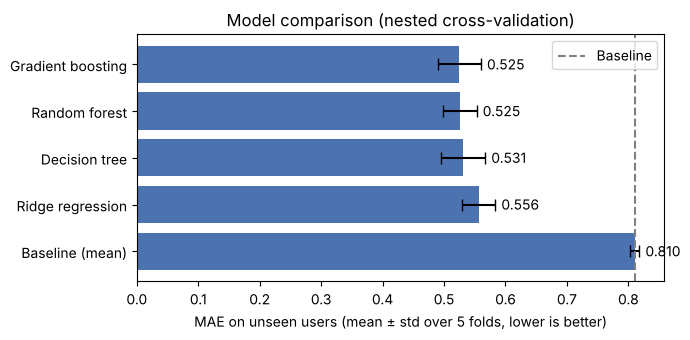

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.5))
order = results.sort_values("MAE", ascending=False)
ax.barh(order["Model"], order["MAE"], xerr=order["MAE std"], color="#4C72B0", capsize=4)
ax.axvline(results.loc[results["Model"] == "Baseline (mean)", "MAE"].item(),
           color="grey", linestyle="--", label="Baseline")
for i, (v, s) in enumerate(zip(order["MAE"], order["MAE std"])):
    ax.text(v + s + 0.01, i, f"{v:.3f}", va="center")
ax.set_xlabel("MAE on unseen users (mean ± std over 5 folds, lower is better)")
ax.set_title("Model comparison (nested cross-validation)")
ax.legend()
plt.tight_layout()
plt.savefig("fig_model_comparison.png", dpi=150)
plt.show()

## 7. Confusion matrix: which scores does the best model get right?

We use the out-of-fold predictions of the best model (lowest MAE), rounded to the closest score.
- **Rows** = real score given by the user, **columns** = predicted score.
- The diagonal = correct predictions.
- The right table shows each row in %: "of all real 5s, how many were predicted as 5?"

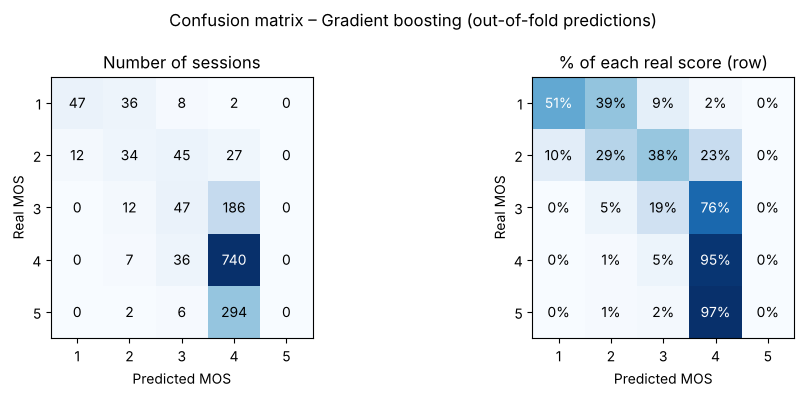

Sessions predicted as each score: {1: 59, 2: 91, 3: 142, 4: 1249, 5: 0}
Real sessions with each score:   {1: 93, 2: 118, 3: 245, 4: 783, 5: 302}


,pred 1,pred 2,pred 3,pred 4,pred 5
real 1,47,36,8,2,0
real 2,12,34,45,27,0
real 3,0,12,47,186,0
real 4,0,7,36,740,0
real 5,0,2,6,294,0


In [12]:
best_name = results.loc[results["Model"] != "Baseline (mean)"].sort_values("MAE").iloc[0]["Model"]
pred_scores = to_score(oof[best_name])

cm = confusion_matrix(y, pred_scores, labels=SCORES)
cm_table = pd.DataFrame(cm, index=[f"real {s}" for s in SCORES], columns=[f"pred {s}" for s in SCORES])
cm_pct = (cm_table.div(cm_table.sum(axis=1), axis=0) * 100).round(0)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, data, title, fmt in [(axes[0], cm, "Number of sessions", "{:.0f}"),
                             (axes[1], cm_pct.to_numpy(), "% of each real score (row)", "{:.0f}%")]:
    ax.imshow(data, cmap="Blues")
    ax.set_xticks(range(5), SCORES)
    ax.set_yticks(range(5), SCORES)
    ax.set_xlabel("Predicted MOS")
    ax.set_ylabel("Real MOS")
    ax.set_title(title)
    for i in range(5):
        for j in range(5):
            color = "white" if data[i, j] > data.max() / 2 else "black"
            ax.text(j, i, fmt.format(data[i, j]), ha="center", va="center", color=color)
fig.suptitle(f"Confusion matrix – {best_name} (out-of-fold predictions)")
plt.tight_layout()
plt.savefig("fig_confusion_matrix.png", dpi=150)
plt.show()

print("Sessions predicted as each score:", {s: int(n) for s, n in zip(SCORES, cm.sum(axis=0))})
print("Real sessions with each score:  ", {s: int(n) for s, n in zip(SCORES, cm.sum(axis=1))})
cm_table

In [13]:
# Average error for each real score: where is the model weakest?
per_score = pd.DataFrame({
    "Real MOS": SCORES,
    "Sessions": [int((y == s).sum()) for s in SCORES],
    "Average prediction": [oof[best_name][y == s].mean() for s in SCORES],
    "MAE": [mean_absolute_error(y[y == s], oof[best_name][y == s]) for s in SCORES],
})
per_score.round(2)

,Real MOS,Sessions,Average prediction,MAE
0,1,93,1.67,0.68
1,2,118,2.70,0.93
2,3,245,3.67,0.83
3,4,783,3.97,0.17
4,5,302,4.01,0.99


**What to look for:**
- Does the model ever predict a **5**? A regression model that minimises the squared error is pulled towards the **average** (about 3.7). For an excellent session the safest guess is often "4", so the model may almost never say 5.
- The same happens for 3s, which are often predicted as 4.
- RMSE and MAE do not show this problem; **macro F1 and the confusion matrix do**.
- → Motivation for the next experiments: **ordinal regression**, **classifiers with class weights**, and **better rounding thresholds**.

## 8. How one setting changes the score (decision tree depth)
A tree that is too shallow is too simple (**underfitting**). A tree that is too deep memorises the training users (**overfitting**).
This plot is only an **illustration** of one setting: we run one grid search on all the data (grouped by user) and show the training error and the cross-validation error for each depth (with `min_samples_leaf = 1`). It is not used to measure the models.

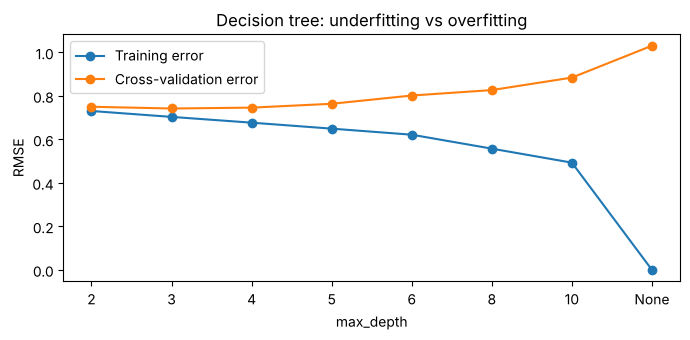

In [14]:
tree_grid = {"model__max_depth": [2, 3, 4, 5, 6, 8, 10, None], "model__min_samples_leaf": [1]}
tree_search = GridSearchCV(make_pipeline(DecisionTreeRegressor(random_state=RANDOM_SEED)), tree_grid,
                           cv=inner_cv, scoring="neg_root_mean_squared_error",
                           return_train_score=True, n_jobs=-1)
tree_search.fit(X, y, groups=groups)

cvres = pd.DataFrame(tree_search.cv_results_)
depth = cvres["param_model__max_depth"].apply(lambda d: "None" if pd.isna(d) else str(int(d)))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(depth, -cvres["mean_train_score"], marker="o", label="Training error")
ax.plot(depth, -cvres["mean_test_score"], marker="o", label="Cross-validation error")
ax.set_xlabel("max_depth")
ax.set_ylabel("RMSE")
ax.set_title("Decision tree: underfitting vs overfitting")
ax.legend()
plt.tight_layout()
plt.savefig("fig_tree_depth.png", dpi=150)
plt.show()

## 9. Extra experiment: with the QoF columns (data leakage)
We run the **same nested cross-validation** for the random forest, but now **with** the 4 QoF columns.
If the error drops a lot, it confirms that QoF is almost the answer. This score is **not** a fair result, because QoF is not available when we want to predict MOS.

In [15]:
leak_numeric = NUMERIC_FEATURES + LEAKAGE_FEATURES
X_leak = df[leak_numeric + CATEGORICAL_FEATURES]
rf_estimator, rf_grid = models["Random forest"]
leak_folds, _, _ = nested_cv(rf_estimator, rf_grid, X_leak, y, groups, numeric_cols=leak_numeric)

honest = all_folds["Random forest"]
leak_table = pd.DataFrame({
    "Random forest": ["without QoF (honest)", "with QoF (leakage)"],
    **{m: [f"{honest[m].mean():.3f} ± {honest[m].std():.3f}",
           f"{leak_folds[m].mean():.3f} ± {leak_folds[m].std():.3f}"]
       for m in ["RMSE", "MAE", "QWK", "Macro F1"]},
})
leak_table

,Random forest,RMSE,MAE,QWK,Macro F1
0,without QoF (honest),0.707 ± 0.037,0.525 ± 0.028,0.680 ± 0.039,0.399 ± 0.050
1,with QoF (leakage),0.436 ± 0.021,0.275 ± 0.018,0.887 ± 0.014,0.728 ± 0.058


## 10. Which features matter most? (permutation importance)
Idea: take the best model, **shuffle one column** in the test fold, and see how much the error grows.
If the error grows a lot, the model really needs this column.
We do it in **each of the 5 outer folds** (always on users the model has never seen) and take the average.

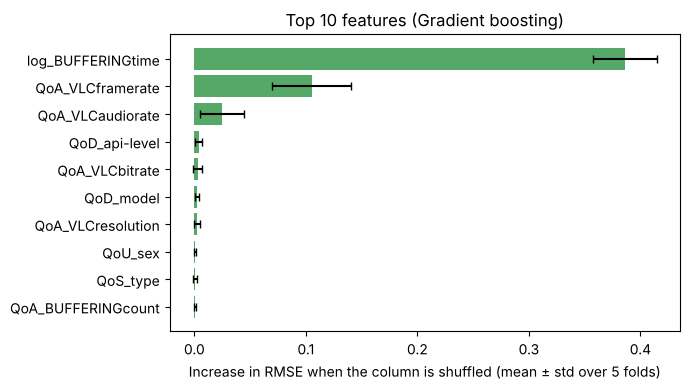

,Feature,RMSE increase,std over folds
7,log_BUFFERINGtime,0.386,0.028
2,QoA_VLCframerate,0.105,0.035
4,QoA_VLCaudiorate,0.025,0.020
8,QoD_api-level,0.004,0.003
1,QoA_VLCbitrate,0.003,0.004
14,QoD_model,0.003,0.002
0,QoA_VLCresolution,0.002,0.002
9,QoU_sex,0.001,0.001
12,QoS_type,0.000,0.002
6,QoA_BUFFERINGcount,0.000,0.001


In [16]:
fold_importances = []
for search, te in fits[best_name]:
    perm = permutation_importance(search.best_estimator_, X.iloc[te], y[te],
                                  scoring="neg_root_mean_squared_error",
                                  n_repeats=20, random_state=RANDOM_SEED, n_jobs=-1)
    fold_importances.append(perm.importances_mean)
fold_importances = np.array(fold_importances)

importance = (pd.DataFrame({"Feature": MAIN_FEATURES,
                            "RMSE increase": fold_importances.mean(axis=0),
                            "std over folds": fold_importances.std(axis=0)})
              .sort_values("RMSE increase", ascending=False))

top = importance.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top["Feature"], top["RMSE increase"], xerr=top["std over folds"], color="#55A868", capsize=3)
ax.set_xlabel("Increase in RMSE when the column is shuffled (mean ± std over 5 folds)")
ax.set_title(f"Top 10 features ({best_name})")
plt.tight_layout()
plt.savefig("fig_feature_importance.png", dpi=150)
plt.show()

importance.round(3)

## 11. Save the results

In [17]:
results.to_csv("results_models.csv", index=False)
pd.concat(all_folds, names=["Model"]).to_csv("results_models_per_fold.csv")
chosen.to_csv("results_best_settings.csv", index=False)
single_splits.to_csv("results_single_split.csv", index=False)
cm_table.to_csv("results_confusion_matrix.csv")
leak_table.to_csv("results_leakage.csv", index=False)
importance.to_csv("results_importance.csv", index=False)
print("Saved: 7 results tables (.csv) and 4 figures (.png)")

Saved: 7 results tables (.csv) and 4 figures (.png)
